<a href="https://colab.research.google.com/github/mtzwyu/machine-learning/blob/main/Tuan1_Regression/BAI_TAP_TREN_LOP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài 1. Giả sử có một tập dữ liệu giả định với các cột Diện tích nhà (m2) và Giá bán (triệu VND).
1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán Giá bán dựa trên
Diện tích nhà.
2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào.
3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình.



In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
np.random.seed(42)

In [4]:
N = 1000
dien_tich = 30 + 120 * np.random.rand(N, 1)

noise = np.random.randn(N, 1) * 400
gia_ban = 500 + 35 * dien_tich + noise

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    dien_tich, gia_ban, test_size=0.2, random_state=42
)
model_simple = LinearRegression()
model_simple.fit(X_train, y_train)

LinearRegression()

In [6]:
# Dự đoán trên tập kiểm tra
y_pred = model_simple.predict(X_test)

# Đánh giá mô hình
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [8]:
print(f"Hệ số chặn (Intercept): {model_simple.intercept_[0]:.2f}")
print(f"Hệ số góc (Slope): {model_simple.coef_[0][0]:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R^2 score: {r2:.4f}")

Hệ số chặn (Intercept): 593.53
Hệ số góc (Slope): 34.41
Mean Squared Error (MSE): 137179.59
R^2 score: 0.9135


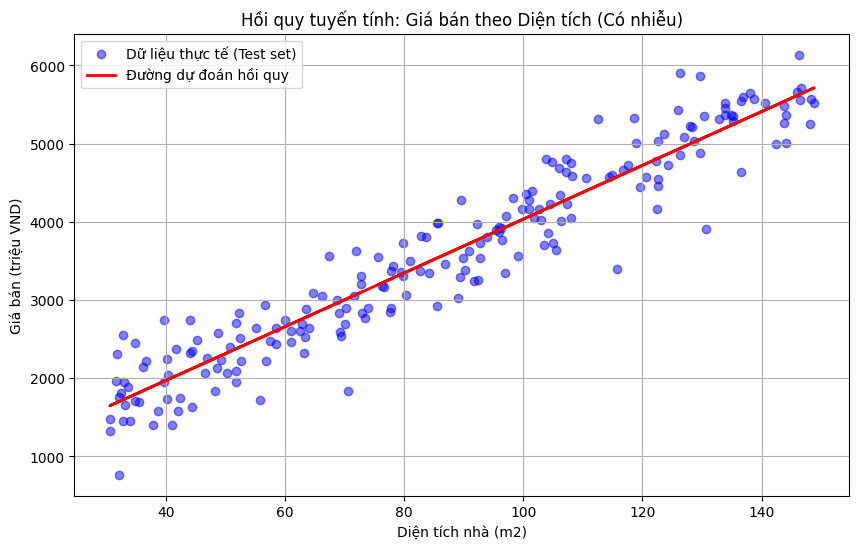

In [9]:
plt.figure(figsize=(10, 6))
plt.scatter(X_test, y_test, color="blue", alpha=0.5, label="Dữ liệu thực tế (Test set)")
plt.plot(X_test, y_pred, color="red", linewidth=2, label="Đường dự đoán hồi quy")
plt.title("Hồi quy tuyến tính: Giá bán theo Diện tích (Có nhiễu)")
plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.legend()
plt.grid(True)
plt.show()

# Bài 2. Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI
- Giả sử có một tập dữ liệu với các thông tin sau:
- BMI: Chỉ số khối cơ thể của bệnh nhân (Body Mass Index).
- Mắc bệnh: Nhãn mục tiêu là 1 nếu bệnh nhân mắc bệnh và 0 nếu không mắc bệnh.
Yêu cầu:
1. - Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic
(BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn).
2. - Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy logistic.
3. - Huấn luyện mô hình trên tập dữ liệu mẫu.
4. - Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra.
5. - Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn.
6. - Trực quan hóa dữ liệu và đường hồi quy logistic.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns


In [12]:
# Yêu cầu 1: Tạo dữ liệu mẫu giả lập (BMI và Nhãn Mắc bệnh)
np.random.seed(42)
n_samples = 300
# Chỉ số BMI thực tế thường dao động trong khoảng từ 15 đến 40
bmi = np.random.uniform(15, 40, size=(n_samples, 1))

# Mối liên hệ logic: BMI cao làm tăng xác suất mắc bệnh thông qua hàm Sigmoid
# Ngưỡng trung gian chọn ở mức BMI ≈ 25
z = 0.45 * (bmi - 25)
prob = 1 / (1 + np.exp(-z))

# Sinh nhãn: 1 nếu xác suất > số ngẫu nhiên [0, 1), ngược lại là 0
y = (np.random.rand(n_samples, 1) < prob).astype(int).ravel()


# Chia tập dữ liệu thành tập huấn luyện (80%) và kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(
    bmi, y, test_size=0.2, random_state=42
)

In [16]:
# Yêu cầu 2: Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy Logistic
model_logistic = LogisticRegression()

# Yêu cầu 3: Huấn luyện mô hình trên tập dữ liệu mẫu.
model_logistic.fit(X_train, y_train)


LogisticRegression()

In [18]:
# Yêu cầu 4: Dự đoán xác suất và nhãn mắc bệnh cho một tập dự liệu kiểm tra
y_pred_prob = model_logistic.predict_proba(X_test)[:, 1]
y_pred = (y_pred_prob >= 0.5).astype(int)

In [24]:
# Yêu cầu 5: Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

In [25]:
print(f"Độ chính xác (Accuracy): {accuracy}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(conf_matrix)
print("Báo cáo phân loại (Classification Report):")
print(classification_rep)

Độ chính xác (Accuracy): 0.9
Ma trận nhầm lẫn (Confusion Matrix):
[[21  3]
 [ 3 33]]
Báo cáo phân loại (Classification Report):
              precision    recall  f1-score   support

           0       0.88      0.88      0.88        24
           1       0.92      0.92      0.92        36

    accuracy                           0.90        60
   macro avg       0.90      0.90      0.90        60
weighted avg       0.90      0.90      0.90        60



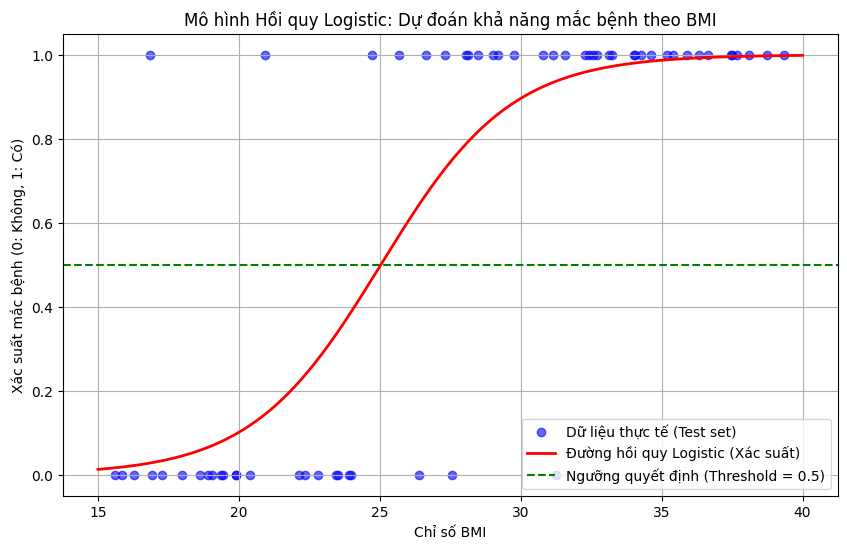

In [26]:
# Yêu cầu 6: Trực quan hóa dữ liệu và đường cong Sigmoid
# Tạo dải giá trị BMI liên tục từ 15 đến 40 để vẽ đường cong mượt
bmi_range = np.linspace(15, 40, 300).reshape(-1, 1)
prob_curve = model_logistic.predict_proba(bmi_range)[:, 1]

plt.figure(figsize=(10, 6))

# Vẽ các điểm dữ liệu thực tế trên tập kiểm tra
plt.scatter(X_test, y_test, color='blue', alpha=0.6, label='Dữ liệu thực tế (Test set)')

# Vẽ đường cong xác suất sigmoid từ mô hình
plt.plot(bmi_range, prob_curve, color='red', linewidth=2, label='Đường hồi quy Logistic (Xác suất)')

# Vẽ đường ngưỡng quyết định 0.5
plt.axhline(0.5, color='green', linestyle='--', label='Ngưỡng quyết định (Threshold = 0.5)')

plt.title("Mô hình Hồi quy Logistic: Dự đoán khả năng mắc bệnh theo BMI")
plt.xlabel("Chỉ số BMI")
plt.ylabel("Xác suất mắc bệnh (0: Không, 1: Có)")
plt.legend()
plt.grid(True)
plt.show()

# Bài 3. Hãy chọn 1 bộ dữ liệu tùy ý (HD: có thể tham khảo trên các trang mạng, ví dụ như Kaggle) và thực hiện các bước cần thiết để có được mô hình hồi qui ứng với bộ dữ liệu đã chọn.

In [45]:
from sklearn.datasets import fetch_california_housing
from sklearn.preprocessing import StandardScaler
import pandas as pd

In [29]:
# Bước 1 tải dữ liệu
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("5 dòng đầu tiên của bộ dữ liệu:")
print(df.head())

5 dòng đầu tiên của bộ dữ liệu:
   MedInc  HouseAge  AveRooms  ...  Latitude  Longitude  MedHouseVal
0  8.3252      41.0  6.984127  ...     37.88    -122.23        4.526
1  8.3014      21.0  6.238137  ...     37.86    -122.22        3.585
2  7.2574      52.0  8.288136  ...     37.85    -122.24        3.521
3  5.6431      52.0  5.817352  ...     37.85    -122.25        3.413
4  3.8462      52.0  6.281853  ...     37.85    -122.25        3.422

[5 rows x 9 columns]


In [32]:
# Bước 2: Khám phá và kiểm tra tiền xử lý dữ liệu
X = housing.data # X là biến độc lập nó chứa cacs thuộc tính như thu nhập, tuổi nhà, số phòng
y = housing.target # y là biến phụ thuộc nó chứa giá nhà trung bình (đơn vị 100000 USD)

print("\nKiểm tra giá trị thiếu (missing values):")
print(X.isnull().sum())



Kiểm tra giá trị thiếu (missing values):
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64


In [36]:
# Bước 3: Phân chia tập huấn luyện và kiểm tra (80% - 20%)

X_train, X_test, y_train, y_test = train_test_split(X, y,  test_size = 0.2, random_state = 42,)

In [38]:
# Bước 4: Chuẩn hóa dữ liệu (Feature Scaling)
scaler = StandardScaler()
# Giúp các đặc trưng có thang đo đồng nhất, mô hình học ổn định hơn
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [40]:
# Bước 5: Khởi tạo và huấn luyện mô hình Linear Regression
model = LinearRegression()
model.fit(X_train_scaled, y_train)


LinearRegression()

In [41]:
y_pred = model.predict(X_test_scaled)

In [43]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Hệ số chặn (Intercept): {model.intercept_:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R^2 score: {r2:.4f}")

Hệ số chặn (Intercept): 2.0719
Mean Squared Error (MSE): 0.5559
R^2 score: 0.5758


In [47]:
coefficients = pd.DataFrame({
    'Thuộc tính': housing.feature_names,
    'Hệ số (Weight)': model.coef_
}).sort_values(by='Hệ số (Weight)', ascending=False)

print("Ảnh hưởng của từng thuộc tính lên giá nhà:")
print(coefficients.to_string(index=False))

Ảnh hưởng của từng thuộc tính lên giá nhà:
Thuộc tính  Hệ số (Weight)
    MedInc        0.854383
 AveBedrms        0.339259
  HouseAge        0.122546
Population       -0.002308
  AveOccup       -0.040829
  AveRooms       -0.294410
 Longitude       -0.869842
  Latitude       -0.896929


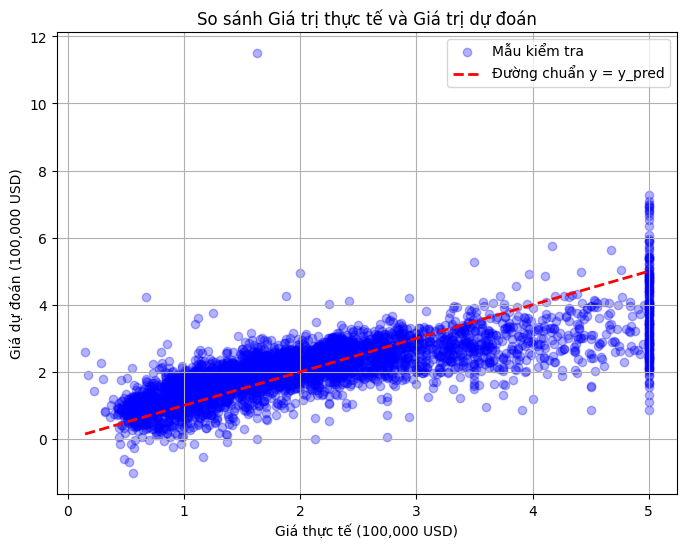

In [48]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue', label='Mẫu kiểm tra')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Đường chuẩn y = y_pred')
plt.title("So sánh Giá trị thực tế và Giá trị dự đoán")
plt.xlabel("Giá thực tế (100,000 USD)")
plt.ylabel("Giá dự đoán (100,000 USD)")
plt.legend()
plt.grid(True)
plt.show()